In Chapters 17 and 18, we forecast with recurrent networks. A Recurrent Neural Network (RNN) reads a series one step at a time and carries everything it knows about the past in a state vector, so information from $k$ steps back has to survive $k$ updates of that state. The Long Short-Term Memory (LSTM) network of Chapter 18 made this easier with its gated cell state, but the trained network kept at most 1.3% of its cell state over 24 hours, and it never learned to use the load one week earlier, the information that anticipates the low days of the week.

The **transformer**, introduced by Vaswani et al. in 2017 for machine translation, drops recurrence altogether. It processes all the items of a sequence in parallel, and a new kind of layer, the **attention layer**, lets every item read directly from every other item, however far back. Transformers have since become the backbone of large foundation models such as the Generative Pre-trained Transformer (GPT), Bidirectional Encoder Representations from Transformers (BERT) and the Vision Transformer (ViT), and of a growing family of time series models.

In this chapter, we follow the flow of data through a transformer: how the inputs are cut into tokens and represented by embeddings, how queries, keys and values define attention, how a self-attention layer works with one head and with several, and the two details that make attention work on ordered sequences, positional embeddings and causal masking. We then forecast the Rome electricity load of Chapters 16 to 18 with attention, first with fixed projections and no training at all, and then with a small transformer that we write and train ourselves.

# Learning objectives

By the end of this lecture, you should be able to

1. explain how a transformer differs from an RNN: auto-regressive next-token prediction, stacked blocks of attention and feed-forward layers, and parallel processing of the whole sequence;
2. explain how a sequence is cut into tokens and represented by embeddings, for text and for a time series, and measure the similarity of two embeddings with a dot product;
3. compute the queries, keys and values, the attention weights and the output of a self-attention head, explain the scaling by $\sqrt{d_k}$, and write the computation in matrix form;
4. explain multi-head self-attention, permutation equivariance, positional embeddings and causal masking, and check each of them numerically;
5. forecast a time series with attention, both with fixed projections (a forecast by analogues) and with a small transformer trained by backpropagation;
6. compare the transformer with the benchmarks of Chapters 16 to 18, and look inside it at what its attention heads look at.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `numpy` | `exp`, `random.default_rng`, matrix products, `lib.stride_tricks.sliding_window_view` -- attention and the transformer itself |
| `pandas` | `read_csv`, `DataFrame` |
| `matplotlib.pyplot` | `subplots`, `plot`, `imshow` |
| `time` | `perf_counter` -- timing the fits |

As in Chapters 17 and 18, we write everything ourselves in NumPy. Attention is a few matrix products and a softmax, and the transformer, with its backward pass and its optimizer, takes about 100 lines. At the end of the chapter, we show the same model in PyTorch for reference.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4) and the MSE (Chapter 6).

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)

---

# Transformers overview

Transformers are designed for sequential data such as text. At their core, they are typically **auto-regressive**: they generate a sequence one token at a time, and each token is predicted from the tokens before it. Suppose that the training data contain the sentence "A robot must obey the orders given it by human beings", the second law of robotics. The training objective is to predict every token from the ones before it: given "A", the model should give a high probability to "robot"; given "A robot", to "must"; and so on. At every position, the output is a probability distribution over the vocabulary, and training pushes up the probability of the token that actually comes next.

<img src="media/Transformer/auto-regressive.png" style="width: 65%; display: block; margin: auto;">

This is the idea of the autoregressive models of Chapters 9 and 10, where $x(t)$ is predicted from $x(t-1), x(t-2), \dots$ For a time series, the output is a number, or a vector of numbers, instead of a distribution over a vocabulary, and the loss is the mean squared error instead of the cross-entropy.

A transformer applies a stack of identical **blocks**, and each block refines the representation of every item of the sequence. A block has two sub-layers:

- an **attention layer**, which mixes information across the positions of the sequence, so that each position can draw on any other one, however far apart they are;
- a **feed-forward network**, the Multi-Layer Perceptron (MLP) of Chapter 16, applied to each position separately, which adds nonlinear transformations.

A notable strength of transformers is **parallel processing**. An RNN must compute its states one after the other, because $\mathbf{h}(t)$ needs $\mathbf{h}(t-1)$. A transformer has no such recursion: it processes all positions at once, with a few large matrix products, which is what made it feasible to train the very large and deep models of today. It also shortens the path between two distant positions to a single attention step, where an RNN needs one step per time lag.

Two more components, positional embeddings and causal masking, make the attention layer work on ordered sequences. We cover them after the attention layer itself.

---

# Tokens and embeddings

Two key components of any machine learning system are the representation of the data and the model that performs the task. Computers have no natural way of representing human language, so Natural Language Processing (NLP) represents words by vectors of floating-point numbers, the **word embeddings**, chosen so that they capture meaning: words that are related for us, such as "dog" and "cat", should have more similar vectors than unrelated words, such as "cat" and "table". The similarity of two embeddings $\mathbf{u}$ and $\mathbf{v}$ is commonly measured by their dot product $\mathbf{u}^\top \mathbf{v}$, or by the **cosine similarity** $\mathbf{u}^\top \mathbf{v} / (\|\mathbf{u}\|\,\|\mathbf{v}\|)$, which divides out the lengths of the vectors and lies between $-1$ and $1$.

The items that a model reads and processes are called **tokens**. Text is usually not split into whole words but into smaller pieces, akin to syllables: "evaluation" may enter a model as the three tokens "eval + ua + tion". A model works with a fixed vocabulary of valid tokens, typically on the order of 40,000, and stores one learned embedding per token. How to build the vocabulary, how large to make it, how to handle digits and punctuation, and how to split languages without clear word boundaries, such as Chinese or Japanese, are open research problems.

**Tokens for a time series.** A time series has no vocabulary: its values are numbers, not symbols. The simplest choice is one token per time step, but a single number makes a poor token, because it says almost nothing on its own. Many transformers for time series therefore cut the series into **patches** of consecutive values, as the PatchTST model of Nie et al. (2023) does, and map each patch $\mathbf{p}_j$ to its embedding with a learned linear layer,

$$\mathbf{x}_j = \mathbf{W}_e^\top \mathbf{p}_j + \mathbf{b}_e,$$

which takes the place of the vocabulary's table of embeddings. For an hourly load, a natural patch is one day, 24 values.

We cut the first 3,000 hours of the Rome load of Chapters 16 to 18 into 125 patches of 24 hours, which we call days (the file has no time stamps, so a day here starts at the first hour of the series, not necessarily at midnight). We standardize the series with the mean and the standard deviation of the 2,700 training hours of those chapters, use the standardized patches themselves as embeddings ($\mathbf{W}_e = \mathbf{I}$, $\mathbf{b}_e = \mathbf{0}$), and compute the cosine similarity of every pair of days.

days most similar to day 116: [123 109  81  86  90]   similarity: [1.   0.98 0.93 0.92 0.92]
similarity to the day before and the day after: 0.86, 0.81


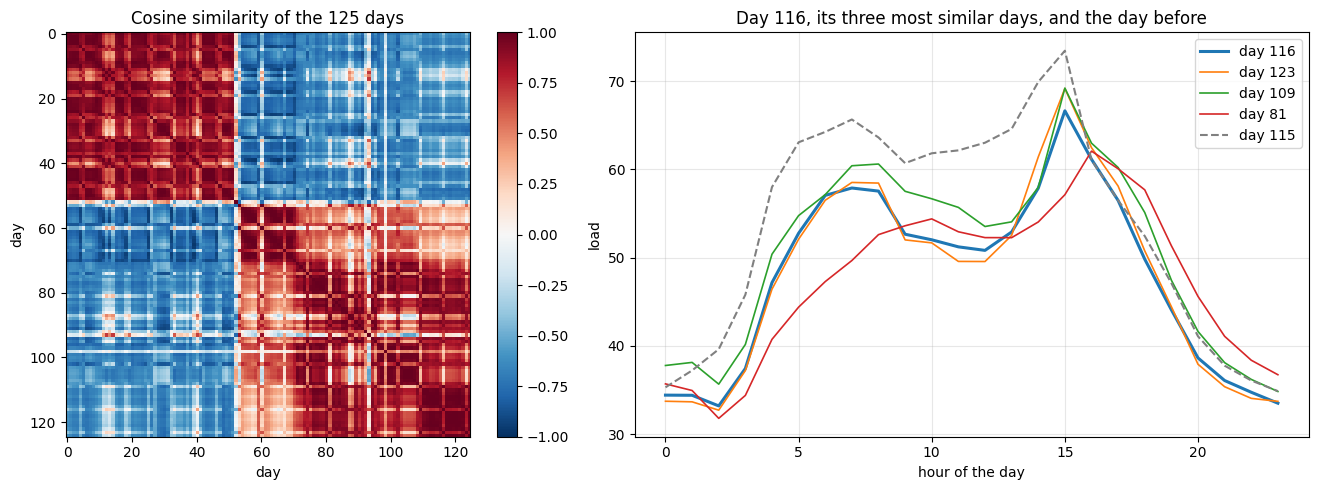

In [3]:
rome = pd.read_csv("data/elec_rome_hourly.csv", index_col="step")["load"]
time_series = rome.to_numpy()[:3000]
n_train = int(0.9 * len(time_series))                  # 2,700 training hours, as in Chapters 16-18
mean, std = time_series[:n_train].mean(), time_series[:n_train].std()
x_scaled = (time_series - mean) / std

days = x_scaled.reshape(-1, 24)                        # 125 tokens of 24 hours
norms = np.linalg.norm(days, axis=1)
similarity = days @ days.T / np.outer(norms, norms)    # cosine similarity of every pair of days

day = 116
closest = np.argsort(similarity[day])[::-1][1:6]       # skip the day itself
print(f"days most similar to day {day}:", closest, "  similarity:", np.round(similarity[day, closest], 2))
print(f"similarity to the day before and the day after: {similarity[day, day - 1]:.2f}, "
      f"{similarity[day, day + 1]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.25]})
im = axes[0].imshow(similarity, cmap="RdBu_r", vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[0].set(title="Cosine similarity of the 125 days", xlabel="day", ylabel="day")
for j in [day, *closest[:3]]:
    axes[1].plot(np.arange(24), time_series[24 * j:24 * (j + 1)], lw=2.2 if j == day else 1.2,
                 label=f"day {j}")
axes[1].plot(np.arange(24), time_series[24 * (day - 1):24 * day], color="gray", ls="--", label=f"day {day - 1}")
axes[1].set(title=f"Day {day}, its three most similar days, and the day before",
            xlabel="hour of the day", ylabel="load")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

The heat map has two large blocks. The days before day 52 are similar to each other and dissimilar to the later days, and the other way around: the shape of the daily profile changes around day 52 (hour 1,250). Within each block, thin light stripes repeat every 7 days: the low days of each week, which differ from the working days. Day 116, the first low day of the test period (it starts at hour 2,784), is most similar to day 123 (similarity 1.00) and day 109 (0.98), exactly one week after and one week before, and then to day 81, five weeks before. Two other close days, 86 and 90, are not a whole number of weeks away; they may be holidays, which look like Sundays in a load series. The day before, day 115, has a similarity of only 0.86: its profile has a much higher morning plateau.

Even raw patches of the standardized load are thus embeddings in which similar days lie close together. A transformer learns its own embedding $\mathbf{W}_e$, and its attention layer compares tokens through further learned projections of it, as we see next.

---

# Query, key and value

Attention lets a model focus on the most relevant parts of its input. Consider the partial sentence "Anqi forgot ___". Many completions are valid: an article ("the", "an"), a preposition ("to", "about") or a possessive pronoun ("her", "his", "their"). A well-trained model should give a higher probability to "her", because of the name "Anqi" two tokens earlier. To predict the next token, the model has to find the earlier tokens that matter and use what they carry. Attention does this with three vectors per token: a query, a key and a value.

The same question comes up in a time series. To forecast the load 24 hours ahead, which past hours matter? The same hour yesterday and the same hour one week earlier, as the earlier chapters showed, but also, for instance, the last low day or a recent change of level, wherever they happen to be.

## Query vectors

Our goal is for each token to learn how much attention to pay to every token of the sequence, itself included. Each token $\mathbf{x}_i$, a vector of size $d$, gets a **query vector**, which it uses to probe the other tokens,

$$\mathbf{q}_i = \mathbf{W}_q^\top \mathbf{x}_i,$$

where $\mathbf{W}_q$ is a learned $d \times d_k$ matrix, and $d_k$ is a hyperparameter, typically smaller than $d$. A sequence of $n$ tokens gives $n$ queries.

## Key vectors

Each token also gets a **key vector**, which it uses to answer the queries of the other tokens,

$$\mathbf{k}_i = \mathbf{W}_k^\top \mathbf{x}_i,$$

with another learned $d \times d_k$ matrix $\mathbf{W}_k$. The relevance of token $j$ to token $i$ is measured by the dot product $\mathbf{q}_i^\top \mathbf{k}_j$, and the **attention weights** of token $i$ are the softmax of its scaled dot products with all $n$ keys,

$$\mathbf{a}_i = \mathrm{softmax}\left(\frac{\big[\mathbf{q}_i^\top \mathbf{k}_1, \; \mathbf{q}_i^\top \mathbf{k}_2, \; \dots, \; \mathbf{q}_i^\top \mathbf{k}_n\big]}{\sqrt{d_k}}\right) \in \mathbb{R}^{1 \times n},$$

where the softmax of a vector $\mathbf{s}$ has the components $e^{s_j} / \sum_{l} e^{s_l}$. The weights are positive and sum to 1: $a_{ij}$ is the share of its attention that token $i$ pays to token $j$.

## Value vectors

What token $i$ receives from token $j$ is not its key but a third vector, its **value**,

$$\mathbf{v}_j = \mathbf{W}_v^\top \mathbf{x}_j,$$

computed with a third learned matrix $\mathbf{W}_v$. The keys decide *where* to look, and the values decide *what* is passed on.

## Attention output

The output of attention for token $i$ is the weighted sum of the values,

$$\mathbf{z}_i = \sum_{j=1}^{n} a_{ij}\, \mathbf{v}_j \in \mathbb{R}^{d_k},$$

an enriched representation of token $i$, which includes context from the whole sequence, weighted by the learned attention.

**Why divide by $\sqrt{d_k}$?** If the components of $\mathbf{q}_i$ and $\mathbf{k}_j$ are independent, with mean 0 and variance 1, the dot product $\mathbf{q}_i^\top \mathbf{k}_j$ is a sum of $d_k$ products with variance 1, so its variance is $d_k$. Without the scaling, the scores grow with $d_k$, the softmax saturates and puts almost all the weight on a single token, and its gradients become very small, which slows down training. We check this with 10,000 random queries, each scored against 10 random keys.

New self-defined function: `softmax`, over the last axis of an array.

In [4]:
def softmax(S):
    "Softmax over the last axis, exp(s_j) / sum_l exp(s_l), shifted by the maximum for numerical stability."
    E = np.exp(S - S.max(axis=-1, keepdims=True))
    return E / E.sum(axis=-1, keepdims=True)

d_k =  64: std of the scores  8.03, scaled 1.00;  mean largest weight 0.87 unscaled, 0.32 scaled


d_k = 256: std of the scores 16.03, scaled 1.00;  mean largest weight 0.93 unscaled, 0.32 scaled


---

# The self-attention layer

In **self-attention**, the queries, the keys and the values all come from the same input sequence. At a high level, a transformer with self-attention layers maps $\mathbb{R}^{n \times d}$ to $\mathbb{R}^{n \times d}$: it takes in $n$ tokens of dimension $d$ and, through many layers, the most important of which are self-attention layers, returns $n$ tokens of dimension $d$ again. A self-attention layer can have several **heads**. We start with one.

## A single self-attention head

We stack the $n$ input tokens as the rows of a matrix $\mathbf{X} \in \mathbb{R}^{n \times d}$, and in the same way, the queries, the keys and the values as the rows of

$$\mathbf{Q} = \mathbf{X}\mathbf{W}_q, \qquad \mathbf{K} = \mathbf{X}\mathbf{W}_k, \qquad \mathbf{V} = \mathbf{X}\mathbf{W}_v,$$

each of size $n \times d_k$. The attention weights of all the tokens form the **attention matrix**

$$\mathbf{A} = \mathrm{softmax}\left(\frac{\mathbf{Q}\mathbf{K}^\top}{\sqrt{d_k}}\right) \in \mathbb{R}^{n \times n},$$

where the softmax is applied to each row separately. Row $i$ of $\mathbf{Q}\mathbf{K}^\top$ holds the dot products $\mathbf{q}_i^\top \mathbf{k}_j$ of query $i$ with every key $j$, so row $i$ of $\mathbf{A}$ is the vector of weights $\mathbf{a}_i$. The outputs of all the tokens are the rows of

$$\mathbf{Z} = \mathbf{A}\mathbf{V} \in \mathbb{R}^{n \times d_k}.$$

In the literature, the whole computation is written as one operation of three arguments,

$$\mathrm{Attention}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \mathrm{softmax}_{\text{row}}\left(\frac{\mathbf{Q}\mathbf{K}^\top}{\sqrt{d_k}}\right)\mathbf{V}.$$

It is two matrix products and a softmax for all $n$ tokens at once: this is the parallel processing of the overview.

New self-defined function: `attention`, which returns the output and the attention matrix of one head. It accepts an optional mask, which we use later, and also works on stacks of sequences, as long as the last two axes hold the tokens and their features.

In [5]:
def attention(Q, K, V, mask=None):
    """Attention(Q, K, V) = softmax_row(Q K^T / sqrt(d_k) + mask) V. Returns the output Z and the
    attention matrix A. The tokens are on the second-to-last axis of Q, K and V."""
    d_k = Q.shape[-1]
    scores = Q @ np.swapaxes(K, -1, -2) / np.sqrt(d_k)
    if mask is not None:
        scores = scores + mask
    A = softmax(scores)
    return A @ V, A

## Multi-head self-attention

Human language is nuanced. Words have tenses, genders, abbreviations, implied meanings and cultural references, and it is unreasonable to expect a single set of $\{\mathbf{Q}, \mathbf{K}, \mathbf{V}\}$ matrices to capture all of them. **Multi-head attention** uses several heads instead, each with its own independently learned projections, so that each head can attend to different parts of the input and model a different kind of relationship.

With $H$ heads, the $h$th head projects the input $\mathbf{X} \in \mathbb{R}^{n \times d}$ with its own matrices $\mathbf{W}_q^h$, $\mathbf{W}_k^h$ and $\mathbf{W}_v^h$, each of size $d \times d_k$, and computes its own attention,

$$\mathbf{Q}^h = \mathbf{X}\mathbf{W}_q^h, \qquad \mathbf{K}^h = \mathbf{X}\mathbf{W}_k^h, \qquad \mathbf{V}^h = \mathbf{X}\mathbf{W}_v^h, \qquad \mathbf{Z}^h = \mathrm{Attention}(\mathbf{Q}^h, \mathbf{K}^h, \mathbf{V}^h) \in \mathbb{R}^{n \times d_k}.$$

The outputs of the $H$ heads are concatenated side by side and projected back to size $d$,

$$\mathbf{Z}^{\text{concat}} = \mathrm{Concat}(\mathbf{Z}^1, \dots, \mathbf{Z}^H) \in \mathbb{R}^{n \times H d_k}, \qquad \mathbf{O} = \mathrm{MultiHead}(\mathbf{X}) = \mathbf{Z}^{\text{concat}}\, \mathbf{W}_o \in \mathbb{R}^{n \times d},$$

where row $i$ of $\mathbf{Z}^{\text{concat}}$ places the $H$ head outputs of token $i$ side by side, and $\mathbf{W}_o$ is a learned $H d_k \times d$ output projection. Typically, $H d_k = d$: GPT-2, for example, has $H = 12$ heads of size $d_k = 64$ and $d = 12 \times 64 = 768$. Then $\mathbf{W}_o$ does not change the size; it mixes what the heads found. A multi-head layer then has $4d^2$ weights, the same as a single head of size $d$, so splitting the attention into heads costs no parameters. For GPT-2, that is $4 \times 768^2 \approx 2.4$ million weights per attention layer.

New self-defined function: `multi_head_attention`.

In [7]:
def multi_head_attention(X, W_q, W_k, W_v, W_o, mask=None):
    """MultiHead(X) = Concat(Z^1, ..., Z^H) W_o. W_q, W_k and W_v have shape (H, d, d_k), one projection
    per head, and W_o has shape (H d_k, d). Returns the output and the H attention matrices."""
    heads = [attention(X @ wq, X @ wk, X @ wv, mask) for wq, wk, wv in zip(W_q, W_k, W_v)]
    Z_concat = np.concatenate([Z for Z, _ in heads], axis=-1)
    return Z_concat @ W_o, np.array([A for _, A in heads])


H = 2                                                  # 2 heads of size d_k = 2, so H d_k = d = 4
W_q, W_k, W_v = (rng.normal(size=(H, d, d_k)) for _ in range(3))
W_o = rng.normal(size=(H * d_k, d))
O, A_heads = multi_head_attention(X, W_q, W_k, W_v, W_o)
print("output shape:", O.shape, "  attention matrices:", A_heads.shape)
print("token 1 attends to the 5 tokens with weights", np.round(A_heads[0, 0], 2), "in head 1 and",
      np.round(A_heads[1, 0], 2), "in head 2")

output shape: (5, 4)   attention matrices: (2, 5, 5)
token 1 attends to the 5 tokens with weights [0.05 0.25 0.2  0.26 0.24] in head 1 and [0.04 0.02 0.02 0.85 0.07] in head 2


The two heads see the same tokens through different projections, and they attend differently: token 1 spreads its attention over tokens 2 to 5 in head 1, but puts 0.85 of it on token 4 in head 2. The output projection $\mathbf{W}_o$ then combines what the two heads found into one output of size $d = 4$ per token.

---

# Positional embeddings

You may have noticed that nothing in the attention layer depends on the **order** of the tokens. The scores compare queries with keys, whatever their positions, and the weighted sum of the values is the same in any order. Self-attention is **permutation-equivariant**: if we keep the weights fixed and swap two input tokens $\mathbf{x}_i$ and $\mathbf{x}_j$, the outputs $\mathbf{z}_i$ and $\mathbf{z}_j$ are swapped, and nothing else changes. We check it on the five tokens above, with the two-head layer.

Natural language is not a bag of words: "the dog bit the man" and "the man bit the dog" have the same tokens and different meanings. A time series is not a bag of values either: a forecast from the last week of load must know which day came last. Transformers therefore add a **positional embedding** $\mathbf{p}_i \in \mathbb{R}^d$ to each input token, before the first attention layer,

$$\mathbf{x}_i^* = \mathbf{x}_i + \mathbf{p}_i,$$

so that the input to attention carries both what the token is and where it appears. All later layers work with position-aware representations. There are two main strategies.

- **Learned** positional embeddings: a trainable vector $\mathbf{p}_i$ for each position $i$, learned with all the other parameters, so that the model discovers how best to encode position for its task.
- **Fixed** positional embeddings, such as the **sinusoidal** embeddings of the original transformer paper,

$$p_{i,\,2k} = \sin\left(\frac{i}{10000^{2k/d}}\right), \qquad p_{i,\,2k+1} = \cos\left(\frac{i}{10000^{2k/d}}\right),$$

where $i = 0, 1, \dots, n-1$ is the position of the token and $k = 0, 1, \dots, d/2 - 1$ indexes pairs of dimensions: the even dimensions get a sine and the odd ones a cosine of the same frequency $\omega_k = 10000^{-2k/d}$. The first pair turns fastest, with a period of $2\pi \approx 6.3$ positions, and the periods grow geometrically up to almost $2\pi \times 10000$, so that each position gets a distinct pattern, like the digits of a counter.

The sine-cosine pairs give the sinusoidal embeddings a useful property. By the identity $\sin a \sin b + \cos a \cos b = \cos(a - b)$,

$$\mathbf{p}_i^\top \mathbf{p}_j = \sum_{k=0}^{d/2-1} \cos\big(\omega_k\,(i - j)\big),$$

which depends only on the offset $i - j$, not on where the two tokens are: the similarity of two positions encodes their **relative position**.

For a time series, the position of a token is its time. Besides learned and sinusoidal embeddings, time series transformers often add calendar features, such as the hour of the day or the day of the week, the features of the XGBoost model of Chapter 14, as temporal embeddings.

New self-defined function: `sinusoidal_positions`.

p_i . p_(i+5) for i = 0, 20, 60: [11.7774 11.7774 11.7774]
largest change of p_i . p_(i+m) along i, over all offsets m: 1.7763568394002505e-14


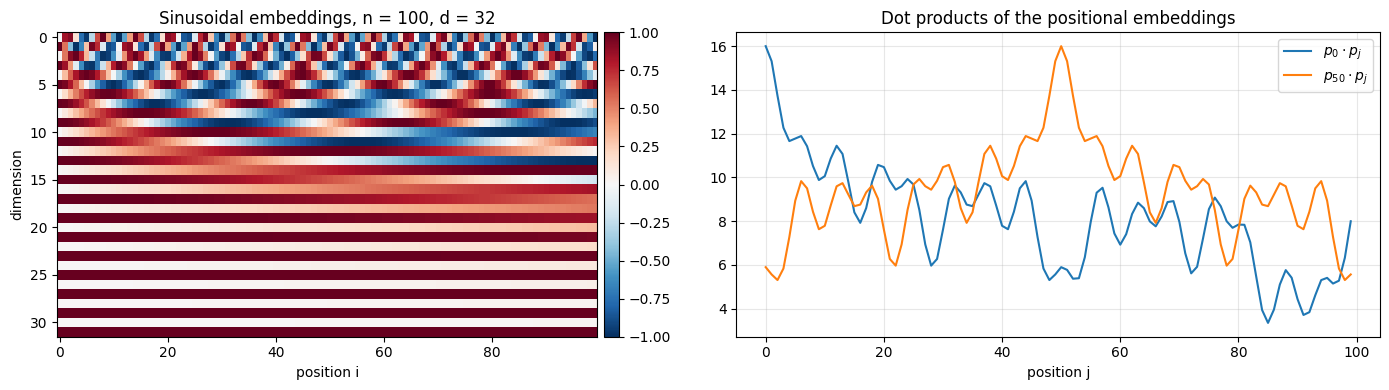

with positions added, reordering only reorders the outputs: False


In [9]:
def sinusoidal_positions(n, d):
    "Sinusoidal positional embeddings of positions 0, ..., n-1, shape (n, d): sine in even, cosine in odd columns."
    i = np.arange(n)[:, None]
    omega = 10000.0 ** (-2 * np.arange(d // 2) / d)
    P = np.empty((n, d))
    P[:, 0::2] = np.sin(i * omega)
    P[:, 1::2] = np.cos(i * omega)
    return P


P = sinusoidal_positions(100, 32)
G = P @ P.T
print("p_i . p_(i+5) for i = 0, 20, 60:", np.round([G[0, 5], G[20, 25], G[60, 65]], 4))
print("largest change of p_i . p_(i+m) along i, over all offsets m:",
      max(np.ptp(np.diag(G, m)) for m in range(100)))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
im = axes[0].imshow(P.T, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[0], pad=0.01)
axes[0].set(title="Sinusoidal embeddings, n = 100, d = 32", xlabel="position i", ylabel="dimension")
for i in [0, 50]:
    axes[1].plot(np.arange(100), G[i], lw=1.5, label=f"$p_{{{i}}} \\cdot p_j$")
axes[1].set(title="Dot products of the positional embeddings", xlabel="position j")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

P_5 = sinusoidal_positions(5, d)                       # positions of the 5 tokens of size d = 4
O_pos, _ = multi_head_attention(X + P_5, W_q, W_k, W_v, W_o)
O_pos_shuffled, _ = multi_head_attention(X[order] + P_5, W_q, W_k, W_v, W_o)
print("with positions added, reordering only reorders the outputs:", np.allclose(O_pos_shuffled, O_pos[order]))

The dot product of two positional embeddings depends only on their offset: $\mathbf{p}_i^\top \mathbf{p}_{i+5} = 11.78$ for every $i$, and over all the offsets, it changes along $i$ by less than $2 \times 10^{-14}$, a rounding error. The heat map shows the counter: the first dimensions oscillate fast, and the last ones hardly move over 100 positions. The dot product $\mathbf{p}_i^\top \mathbf{p}_j$ peaks at $d/2 = 16$ for $j = i$ and is smaller for the other positions, though not monotonically in the distance: nearby positions are similar, and distant ones less so. Once the positions are added, reordering the tokens no longer just reorders the outputs: the layer now knows where each token is.

---

# Causal self-attention

More generally, a **mask** can limit which tokens take part in the attention computation. The most common one limits each query to the tokens at the same or earlier positions. It keeps the attention mechanism from "looking ahead" when a transformer is used to generate one token at a time, and for a time series, it keeps a forecast from using the future. This **causal mask** is an $n \times n$ matrix with zeros on and below the diagonal and $-\infty$ above it,

$$\mathbf{M} = \begin{bmatrix} 0 & -\infty & -\infty & \cdots & -\infty \\ 0 & 0 & -\infty & \cdots & -\infty \\ 0 & 0 & 0 & \cdots & -\infty \\ \vdots & \vdots & \vdots & \ddots & \vdots \\ 0 & 0 & 0 & \cdots & 0 \end{bmatrix},$$

which is added to the scores before the softmax,

$$\mathbf{A} = \mathrm{softmax}\left(\frac{\mathbf{Q}\mathbf{K}^\top}{\sqrt{d_k}} + \mathbf{M}\right), \qquad \mathbf{Z} = \mathbf{A}\mathbf{V}.$$

Since $e^{-\infty} = 0$, query $i$ gives zero weight to the tokens $i + 1, \dots, n$ and attends only to the tokens $1, \dots, i$. The mask must be applied **before** the softmax, so that each row of $\mathbf{A}$ is normalized over the allowed tokens and still sums to 1.

Causal attention is what makes the training of an auto-regressive transformer efficient. With the mask, the output at position $i$ depends only on the tokens up to $i$, so one pass over a sequence of $n$ tokens gives $n$ predictions, each of the next token from its own past, and all of them enter the loss at once, as in the figure of the overview.

New self-defined function: `causal_mask`. We check that the outputs of the first three tokens do not change when we replace the last two tokens, and what happens if we mask after the softmax instead.

In [10]:
def causal_mask(n):
    "n x n mask with 0 on and below the diagonal and -inf above it."
    return np.triu(np.full((n, n), -np.inf), k=1)


M = causal_mask(5)
O_causal, A_causal = multi_head_attention(X, W_q, W_k, W_v, W_o, mask=M)
print("causal attention matrix of head 1:\n", np.round(A_causal[0], 3))

X_new = X.copy()
X_new[3:] = rng.normal(size=(2, d))                    # replace tokens 4 and 5
O_new, _ = multi_head_attention(X_new, W_q, W_k, W_v, W_o, mask=M)
print("outputs 1-3 unchanged:", np.allclose(O_new[:3], O_causal[:3]),
      "  outputs 4-5 unchanged:", np.allclose(O_new[3:], O_causal[3:]))

_, A_full = attention(X @ W_q[0], X @ W_k[0], X @ W_v[0])
A_after = A_full * np.tril(np.ones((5, 5)))            # wrong: mask after the softmax
print("row sums, mask before the softmax:", A_causal[0].sum(axis=1).round(3),
      "  after the softmax:", A_after.sum(axis=1).round(3))

causal attention matrix of head 1:
 [[1.    0.    0.    0.    0.   ]
 [0.876 0.124 0.    0.    0.   ]
 [0.518 0.225 0.256 0.    0.   ]
 [0.609 0.128 0.152 0.111 0.   ]
 [0.392 0.17  0.166 0.131 0.141]]
outputs 1-3 unchanged: True   outputs 4-5 unchanged: False
row sums, mask before the softmax: [1. 1. 1. 1. 1.]   after the softmax: [0.052 0.738 0.688 0.891 1.   ]


The causal attention matrix is lower-triangular: the first token can only attend to itself, with weight 1, and the last one attends to all five. Every row still sums to 1. Replacing the last two tokens changes their own outputs, but not those of tokens 1 to 3: no output depends on a later token. Masking after the softmax instead removes the weights of the later tokens without normalizing again, and the rows then sum to anything between 0.05 and 1. Token 1, which gave only 0.05 of its weight to itself, would get almost no output at all.

---

# Forecasting with attention alone

Before we build and train a full transformer, we use the attention mechanism by itself, with fixed projections and no training at all, to forecast the electricity load. It shows what attention does with a time series: it looks up the past situations that resemble the present one and passes on what followed them.

## The data

We use the same series and the same task as in Chapters 16 to 18: the first 3,000 hours of the Rome load, the first 2,700 hours for training, the last 300 hours for testing, and a forecast $\tau = 24$ hours ahead, so that every method is scored on the same 300 test hours. As in Chapter 18, we hold out the last 300 training hours (2400-2699) as a **validation period** to choose hyperparameters, and the series is standardized with the mean and the standard deviation of the training period.

In [11]:
horizon = 24
n_fit = n_train - 300                                  # hours 2400-2699 are the validation period
origins = np.arange(len(time_series) - horizon)        # a forecast made at hour t ...
targets = origins + horizon                            # ... is a forecast of hour t + 24
val = (targets >= n_fit) & (targets < n_train)
test = targets >= n_train
y_val, y_test = time_series[targets[val]], time_series[targets[test]]
naive_val, naive_test = time_series[origins[val]], time_series[origins[test]]
test_hours = targets[test]
print(f"standardization: mean {mean:.2f}, standard deviation {std:.2f}")
print(f"validation targets: hours {targets[val][0]}-{targets[val][-1]},  "
      f"test targets: hours {test_hours[0]}-{test_hours[-1]}")
print(f"seasonal naive MSE: validation {mse(y_val, naive_val):.2f},  test {mse(y_test, naive_test):.2f}")

standardization: mean 58.26, standard deviation 15.90
validation targets: hours 2400-2699,  test targets: hours 2700-2999
seasonal naive MSE: validation 47.70,  test 22.29


## Attention as a soft lookup

We make every hour $s$ a token: the window $\mathbf{w}(s) = [x(s - L + 1), \dots, x(s)]$ of the last $L$ standardized loads up to $s$, for example the last week, $L = 168$. To forecast $x(t + 24)$ at the origin $t$, we take

- the window of the origin as the **query**, $\mathbf{q}(t) = \mathbf{W}^\top \mathbf{w}(t)$;
- the window of every earlier hour $s$ as a **key**, $\mathbf{k}(s) = \mathbf{W}^\top \mathbf{w}(s)$;
- what happened next as the **value**, $v(s) = x(s + 24) - x(s)$, the change over the following 24 hours,

and forecast the change from the seasonal naive forecast, as in Chapter 18,

$$\hat x(t + 24) = x(t) + \sum_s a_{ts}\, v(s), \qquad \mathbf{a}_t = \mathrm{softmax}_s\left(c\, \frac{\mathbf{q}(t)^\top \mathbf{k}(s)}{\sqrt{d_k}} + M_{ts}\right), \qquad M_{ts} = \begin{cases} 0 & s \le t - 24, \\ -\infty & s > t - 24. \end{cases}$$

This is the masked attention of the previous sections, with $d_k = L$, one query per forecast origin, and a mask that also hides the last 23 hours before the origin, whose values $v(s)$ are not yet known at time $t$. The factor $c$ sharpens the softmax: with $c = 1$, we have the standard scaling, and larger values of $c$ give more weight to the most similar windows and less to the others.

It is also an old forecasting method in disguise. The **method of analogues**, used in weather forecasting since Lorenz (1969), and the **similar-day method** of electricity load forecasting both look up the past situations most similar to the present one and average what happened next. Softmax attention is a smooth version of them: every past window contributes, in proportion to the exponential of its similarity to the present window. In statistics, the same estimator is known as kernel regression.

Instead of learning $\mathbf{W}_q = \mathbf{W}_k = \mathbf{W}$, we try two fixed projections:

- the **identity**, $\mathbf{W} = \mathbf{I}$, which compares the raw windows, levels included;
- the **centering matrix**, $\mathbf{W} = \mathbf{I} - \frac{1}{L}\mathbf{1}\mathbf{1}^\top$, which subtracts its mean from each window, so that windows are compared by their shape only, whatever their level.

We also try windows of one day and one week, and $c = 1, 2, 4$, and we choose the combination with the lowest validation MSE. To see how many past windows share the attention, we report the **effective number of keys**, $1 / \sum_s a_{ts}^2$: it equals $m$ when the weight is spread evenly over $m$ keys.

New self-defined function: `analog_forecast`.

In [12]:
def analog_forecast(idx, window=168, center=True, sharpness=1.0):
    """Attention forecasts of x(t + 24) at the origins t = origins[idx], in load units, and the attention
    matrix. Each hour s is a token, the window of the last `window` loads up to s. Queries and keys are the
    windows, centered if `center`; values are the changes x(s + 24) - x(s); the mask hides all s > t - 24."""
    W = np.eye(window) - 1 / window if center else np.eye(window)        # W_q = W_k = W
    hours = np.arange(window - 1, len(origins))                        # the hours s with a full window
    E = sliding_window_view(x_scaled[:len(origins)], window) @ W       # row s - window + 1: W^T w(s)
    values = (x_scaled[hours + horizon] - x_scaled[hours])[:, None]
    t = origins[idx]
    mask = np.where(hours[None, :] <= t[:, None] - horizon, 0.0, -np.inf)
    Z, A = attention(sharpness * E[t - window + 1], E, values, mask)
    return (x_scaled[t] + Z[:, 0]) * std + mean, A


rows = []
for window in [24, 168]:
    for center in [False, True]:
        for sharpness in [1, 2, 4]:
            fc_val, A_val = analog_forecast(val, window, center, sharpness)
            rows.append({"window": window, "projection": "centering" if center else "identity",
                         "sharpness c": sharpness,
                         "effective keys": np.median(1 / np.sum(A_val ** 2, axis=1)),
                         "validation MSE": mse(y_val, fc_val),
                         "test MSE": mse(y_test, analog_forecast(test, window, center, sharpness)[0])})
analog_table = pd.DataFrame(rows)
analog_table.round(2)

,window,projection,sharpness c,effective keys,validation MSE,test MSE
0,24,identity,1,128.95,45.20,26.87
1,24,identity,2,16.73,101.17,161.61
2,24,identity,4,4.76,197.48,473.47
3,24,centering,1,364.55,46.69,22.66
4,24,centering,2,85.98,55.68,26.44
5,24,centering,4,14.18,103.74,47.75
6,168,identity,1,45.59,33.64,16.54
7,168,identity,2,9.52,35.44,12.27
8,168,identity,4,3.41,44.21,11.47
9,168,centering,1,80.62,34.82,15.01


With one-day windows, attention barely beats the seasonal naive forecast on the validation period (45.20 and 46.69 with $c = 1$, against 47.70), it does not beat it on the test period, and sharper settings are far worse: one day says little about what comes next. With one-week windows, every setting beats the seasonal naive forecast on both periods. The sharpness matters a lot. With the standard scaling, $c = 1$, the weight is spread over 46 to 81 effective keys, and the forecast averages many weeks, some of them not very similar to the present one. With $c = 4$, about 3 keys share the weight, and the forecast rests on a few, possibly unlucky, matches. The validation MSE is lowest for one-week windows, centering and $c = 2$ (29.21), with about 10 effective keys. At $c = 2$, centering helps (29.21 against 35.44 without it): the load level changes over the series, and only the shape of the week should matter.

The validation and test periods do not rank every setting the same way: the validation period prefers centering with $c = 1$ (34.82) to the identity with $c = 4$ (44.21), and the test period the other way around (15.01 against 11.47). But they agree on the best setting, whose test MSE, 8.76, is less than half that of the seasonal naive forecast.

chosen on validation: {'window': 168, 'projection': 'centering', 'sharpness c': 2}
test MSE: attention forecast 8.76, seasonal naive 22.29
origin t = 2766: weight within 3 hours of a whole number of weeks back: 0.17 (an even spread would give 0.04)
forecast of hour 2790: 59.8, observed 57.1, seasonal naive 64.2


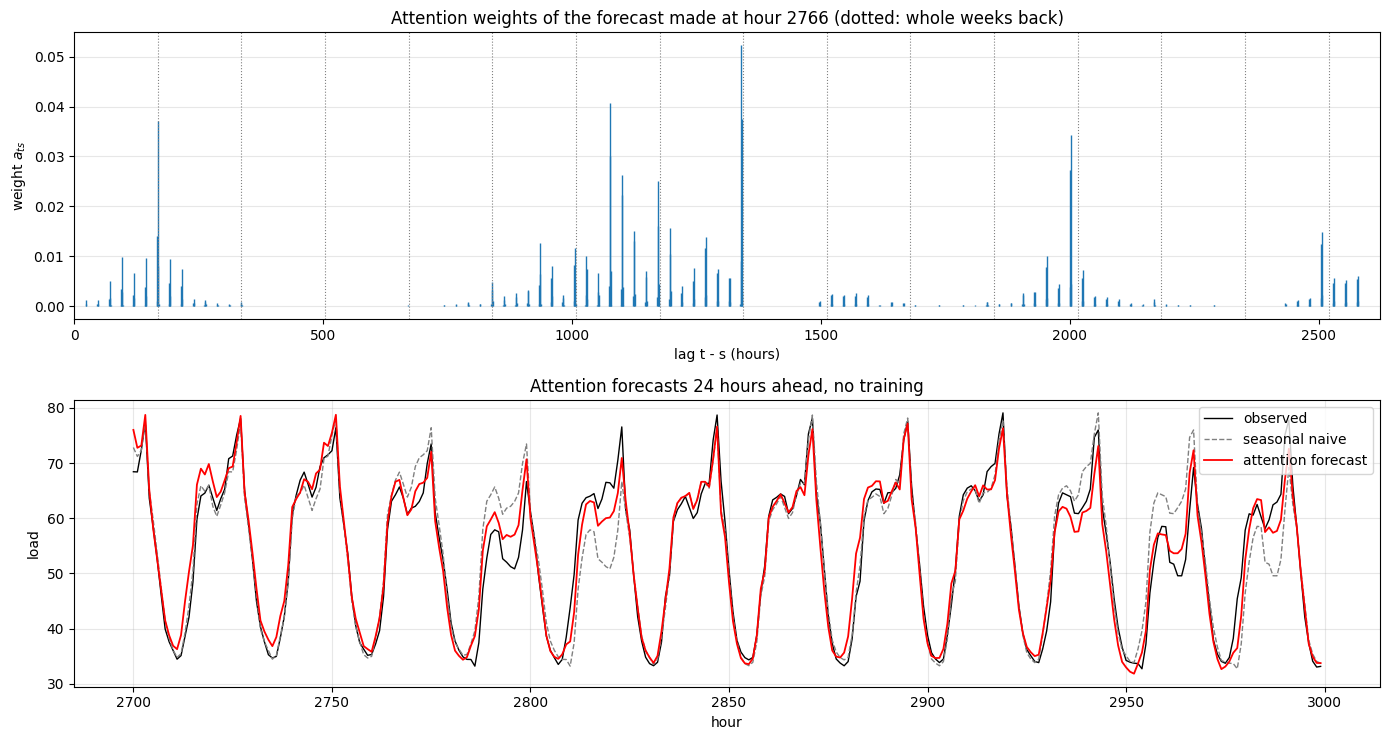

In [13]:
best = analog_table.loc[analog_table["validation MSE"].idxmin()]
print("chosen on validation:", best[["window", "projection", "sharpness c"]].to_dict())
y_analog, A_test = analog_forecast(test, int(best["window"]), best["projection"] == "centering",
                                   best["sharpness c"])
print(f"test MSE: attention forecast {mse(y_test, y_analog):.2f}, seasonal naive {mse(y_test, naive_test):.2f}")

k = np.where(test_hours == 2790)[0][0]                 # the forecast of hour 2790, on a low day
t = origins[test][k]
lags = t - np.arange(int(best["window"]) - 1, len(origins))
weights = A_test[k]
near_week = np.abs((lags + 84) % 168 - 84) <= 3        # within 3 hours of a multiple of one week
print(f"origin t = {t}: weight within 3 hours of a whole number of weeks back: {weights[near_week].sum():.2f} "
      f"(an even spread would give {near_week[weights > 0].mean():.2f})")
print(f"forecast of hour 2790: {y_analog[k]:.1f}, observed {y_test[k]:.1f}, seasonal naive {naive_test[k]:.1f}")

fig, axes = plt.subplots(2, 1, figsize=(14, 7.5))
axes[0].vlines(lags, 0, weights, color="tab:blue", lw=1)
for w in range(1, lags.max() // 168 + 1):
    axes[0].axvline(168 * w, color="gray", ls=":", lw=0.8)
axes[0].set(title=f"Attention weights of the forecast made at hour {t} (dotted: whole weeks back)",
            xlabel="lag t - s (hours)", ylabel="weight $a_{ts}$", xlim=(0, lags.max() + 24))
axes[0].grid(alpha=0.3, axis="y")
run_sequence_plot(y_test, x=test_hours, ax=axes[1], color="black", label="observed",
                  xlabel="hour", ylabel="load", title="Attention forecasts 24 hours ahead, no training")
axes[1].plot(test_hours, naive_test, color="gray", ls="--", lw=1, label="seasonal naive")
axes[1].plot(test_hours, y_analog, color="red", lw=1.3, label="attention forecast")
axes[1].legend()
plt.tight_layout(); plt.show()

The weights of the forecast made at hour 2766, the forecast of the low day at hour 2790, form a comb with teeth 24 hours apart: the windows most similar to the last week end at the same hour of the day as the origin. The tallest teeth are at lags of about 1,340 hours (8 weeks minus 4 hours), 1,076, 168 (exactly one week) and 2,002 hours. The windows within 3 hours of a whole number of weeks back get 17% of the weight, four times their share of the keys, but similar weeks also turn up at other lags. Long stretches of the history get almost no weight at all: their weeks do not look like this one. The forecast of hour 2790 is 59.8, against 57.1 observed and 64.2 for the seasonal naive forecast.

Unlike the MLP, the Echo State Network (ESN) and the LSTM of Chapters 16 to 18, the attention forecast anticipates both low days of the test period, around hours 2790 and 2955, at least in part, and it does not repeat them on the following days, around hours 2815 and 2980. The information that anticipates a low day, that the same day one or several weeks earlier was low, is right there when whole weeks are compared.

---

# The transformer block

A transformer adds learned projections and a few more ingredients to the attention layer. So far, we have described the attention layer in detail and the rest of the block only in words. We now spell out the version we use, the block of GPT-style models without layer normalization.

The input tokens, patches of $P$ values, are embedded and given their positions,

$$\mathbf{E} = \mathbf{X}_p \mathbf{W}_e + \mathbf{1}\mathbf{b}_e^\top + \mathbf{P},$$

where $\mathbf{X}_p \in \mathbb{R}^{n \times P}$ holds the $n$ patches in its rows and $\mathbf{P} \in \mathbb{R}^{n \times d}$ the positional embeddings. A block then applies its two sub-layers, each with a **residual connection**,

$$\mathbf{E}' = \mathbf{E} + \mathrm{MultiHead}_{\mathbf{M}}(\mathbf{E}), \qquad \mathbf{E}'' = \mathbf{E}' + \max\big(0,\; \mathbf{E}'\mathbf{W}_1 + \mathbf{1}\mathbf{b}_1^\top\big)\,\mathbf{W}_2 + \mathbf{1}\mathbf{b}_2^\top,$$

where $\mathrm{MultiHead}_{\mathbf{M}}$ is multi-head self-attention with the causal mask $\mathbf{M}$, and the second sub-layer is the feed-forward network, an MLP with one hidden layer of $d_{\text{ff}}$ Rectified Linear Units (ReLU), $\max(0, a)$, applied to each token (each row) separately. In the original transformer, $d_{\text{ff}} = 4d$. Blocks can be stacked, and a linear output layer maps each token of the last block to the prediction of the next token,

$$\mathbf{Y} = \mathbf{E}''\mathbf{W}_y + \mathbf{1}\mathbf{b}_y^\top.$$

- **Residual connections.** Each sub-layer adds a correction to its input instead of replacing it, the skip connection of Chapter 18. The gradient flows back through the identity path of every block, which is what allows deep stacks of blocks to be trained.
- **Layer normalization.** Transformers usually also normalize each token vector to mean 0 and variance 1 across its $d$ features, followed by a learned scale and shift, before each sub-layer (in GPT-2) or after it (in the original transformer). It stabilizes the training of deep stacks. We leave it out of our model, which has a single block.

The two sub-layers divide the work. Attention is the only place where the tokens exchange information, and it is linear in the values: each output is a weighted average. The feed-forward network adds the nonlinearity, but it sees one token at a time.

---

# A transformer for the load

## Tokens and targets

We now train a small transformer on the forecasting task above. Its tokens are the patches of the attention forecast: at the origin $t$, the input is the last $n = 14$ days (336 hours), cut into 14 patches of 24 hours, $\mathbf{p}_1, \dots, \mathbf{p}_{14}$, the last of which ends at hour $t$. The model is auto-regressive, as in the overview: with the causal mask, token $j$ sees the patches $1, \dots, j$ and predicts the next patch $\mathbf{p}_{j+1}$. As in Chapter 18, it predicts the change from the seasonal naive forecast, $\mathbf{y}_j \approx \mathbf{p}_{j+1} - \mathbf{p}_j$, a skip connection that makes a network with zero output reproduce the seasonal naive forecast. The 24th value of the last token's output is our forecast,

$$\hat x(t + 24) = x(t) + y_{14,\,24}.$$

A training sequence therefore gives 14 predictions of whole days at once. We leave the first six tokens out of the loss, as the washout of Chapters 17 and 18: tokens $7, \dots, 14$ are the ones whose target day has its counterpart one week earlier in their view. We cut the training sequences from the fitting period (targets before hour 2400) at every fifth origin, which gives 409 sequences, and standardize as above. (Cutting them at every hour gives five times more computation for no better forecasts in our tests.)

New self-defined function: `make_patches`.

In [14]:
def make_patches(ends, n_tokens=14, patch=24):
    "The n_tokens patches of `patch` standardized loads that end at each hour t of `ends`: (len(ends), n_tokens, patch)."
    length = n_tokens * patch
    return np.stack([x_scaled[t - length + 1:t + 1].reshape(n_tokens, patch) for t in ends])


fit_ends = np.arange(14 * 24 - 1, n_fit - horizon, 5)  # origins with all targets before hour 2400
X_fit = make_patches(fit_ends)
Y_fit = make_patches(fit_ends + horizon) - X_fit       # next patch minus the current one
mask = np.zeros_like(Y_fit)
mask[:, 6:] = 1                                        # tokens 7-14 enter the loss
print("inputs:", X_fit.shape, "  targets:", Y_fit.shape, f"  values in the loss: {int(mask.sum())}")

inputs: (409, 14, 24)   targets: (409, 14, 24)   values in the loss: 78528


## The model

New self-defined class: `Transformer`. It implements the block of the previous section with the attention, causal mask and positional embeddings of this chapter, computes the gradients of a loss by backpropagation, and fits the weights with full-batch Adam and gradient clipping, like the `LSTM` class of Chapter 18. The projections of the $H$ heads are stored side by side: columns $(h-1)d_k + 1$ to $h\,d_k$ of `W_q` hold $\mathbf{W}_q^h$, and the method `split` cuts the queries into the heads, so that all heads are computed with one call to `attention`. The method `merge` is the concatenation. Unlike the LSTM, the backward pass has no loop over time: like the forward pass, it treats all the positions at once.

Our transformer has $d = 8$, $H = 2$ heads of size $d_k = 4$, a feed-forward network with $d_{\text{ff}} = 16$ hidden units, and one block.

In [15]:
class Transformer:
    """A decoder-only transformer for sequences of patches, with a linear output for every token.

    An input X has shape (B, n, P): B sequences of n tokens, each a patch of P values. The patches are
    embedded, the sinusoidal positions are added (if `positions`), and n_blocks blocks of causal multi-head
    self-attention and a ReLU feed-forward network, both with residual connections, are applied. The output
    Y has shape (B, n, P).
    """

    def __init__(self, patch=24, n_tokens=14, d=8, n_heads=2, d_ff=16, n_blocks=1, positions=True, seed=0):
        rng = np.random.default_rng(seed)
        self.n_heads, self.d_k, self.n_blocks = n_heads, d // n_heads, n_blocks
        init = lambda n_in, shape: rng.uniform(-1, 1, shape) / np.sqrt(n_in)
        p = {"W_e": init(patch, (patch, d)), "b_e": np.zeros(d)}
        for l in range(n_blocks):
            for name in ["W_q", "W_k", "W_v", "W_o"]:   # the H heads side by side
                p[f"{name}{l}"] = init(d, (d, d))
            p[f"W_1{l}"], p[f"b_1{l}"] = init(d, (d, d_ff)), np.zeros(d_ff)
            p[f"W_2{l}"], p[f"b_2{l}"] = init(d_ff, (d_ff, d)), np.zeros(d)
        p["W_y"], p["b_y"] = 0.1 * init(d, (d, patch)), np.zeros(patch)   # outputs start close to 0
        self.params = p
        self.P = sinusoidal_positions(n_tokens, d) if positions else np.zeros((n_tokens, d))
        self.M = causal_mask(n_tokens)

    def split(self, T):
        "(B, n, H d_k) -> (B, H, n, d_k): one slice per head."
        B, n, _ = T.shape
        return T.reshape(B, n, self.n_heads, self.d_k).transpose(0, 2, 1, 3)

    def merge(self, T):
        "(B, H, n, d_k) -> (B, n, H d_k): the heads side by side (Concat)."
        B, H, n, d_k = T.shape
        return T.transpose(0, 2, 1, 3).reshape(B, n, H * d_k)

    def forward(self, X):
        "Outputs of every token, shape (B, n, P), and the values needed by `backward`."
        p, n = self.params, X.shape[1]
        E = X @ p["W_e"] + p["b_e"] + self.P[:n]                    # embeddings plus positions
        cache = {"X": X, "blocks": []}
        for l in range(self.n_blocks):
            Q, K, V = (self.split(E @ p[f"{w}{l}"]) for w in ["W_q", "W_k", "W_v"])
            Z, A = attention(Q, K, V, self.M[:n, :n])               # all heads at once
            Z = self.merge(Z)
            E1 = E + Z @ p[f"W_o{l}"]                               # attention sub-layer, residual
            U = E1 @ p[f"W_1{l}"] + p[f"b_1{l}"]
            R = np.maximum(U, 0)                                    # ReLU
            cache["blocks"].append({"E": E, "Q": Q, "K": K, "V": V, "A": A, "Z": Z, "E1": E1, "U": U, "R": R})
            E = E1 + R @ p[f"W_2{l}"] + p[f"b_2{l}"]                # feed-forward sub-layer, residual
        cache["E"] = E
        return E @ p["W_y"] + p["b_y"], cache

    def backward(self, dY, cache):
        "Gradients of the parameters, given dLoss/dY of shape (B, n, P)."
        p, g = self.params, {}
        flat = lambda T: T.reshape(-1, T.shape[-1])                 # (B, n, k) -> (B n, k)
        g["W_y"], g["b_y"] = flat(cache["E"]).T @ flat(dY), dY.sum(axis=(0, 1))
        dE = dY @ p["W_y"].T
        for l in reversed(range(self.n_blocks)):
            c = cache["blocks"][l]
            # feed-forward sub-layer: E'' = E' + ReLU(E' W_1 + b_1) W_2 + b_2
            g[f"W_2{l}"], g[f"b_2{l}"] = flat(c["R"]).T @ flat(dE), dE.sum(axis=(0, 1))
            dU = (dE @ p[f"W_2{l}"].T) * (c["U"] > 0)
            g[f"W_1{l}"], g[f"b_1{l}"] = flat(c["E1"]).T @ flat(dU), dU.sum(axis=(0, 1))
            dE1 = dE + dU @ p[f"W_1{l}"].T
            # attention sub-layer: E' = E + Concat(A V) W_o, with A = softmax(Q K^T / sqrt(d_k) + M)
            g[f"W_o{l}"] = flat(c["Z"]).T @ flat(dE1)
            dZ = self.split(dE1 @ p[f"W_o{l}"].T)
            dA = dZ @ np.swapaxes(c["V"], -1, -2)
            dV = np.swapaxes(c["A"], -1, -2) @ dZ
            dS = c["A"] * (dA - np.sum(dA * c["A"], axis=-1, keepdims=True)) / np.sqrt(self.d_k)
            dQ, dK = dS @ c["K"], np.swapaxes(dS, -1, -2) @ c["Q"]
            dE = dE1
            for w, dT in (("W_q", dQ), ("W_k", dK), ("W_v", dV)):
                dT = self.merge(dT)
                g[f"{w}{l}"] = flat(c["E"]).T @ flat(dT)
                dE = dE + dT @ p[f"{w}{l}"].T
        g["W_e"], g["b_e"] = flat(cache["X"]).T @ flat(dE), dE.sum(axis=(0, 1))
        return g

    def loss_and_grads(self, X, Y, mask):
        "MSE over the values where mask is 1, and its gradients."
        Y_hat, cache = self.forward(X)
        err = (Y_hat - Y) * mask
        n = mask.sum()
        return np.sum(err ** 2) / n, self.backward(2 * err / n, cache)

    def fit(self, X, Y, mask, epochs=100, lr=0.005, clip=1.0, callback=None):
        """Full-batch Adam with gradient clipping. Returns the training loss of every epoch;
        callback(self), if given, is called after every epoch."""
        m = {k: np.zeros_like(w) for k, w in self.params.items()}
        v = {k: np.zeros_like(w) for k, w in self.params.items()}
        losses = []
        for step in range(1, epochs + 1):
            loss, grads = self.loss_and_grads(X, Y, mask)
            norm = np.sqrt(sum(np.sum(gr ** 2) for gr in grads.values()))
            if norm > clip:                                         # gradient clipping
                grads = {k: gr * clip / norm for k, gr in grads.items()}
            for k, w in self.params.items():                        # Adam update
                m[k] = 0.9 * m[k] + 0.1 * grads[k]
                v[k] = 0.999 * v[k] + 0.001 * grads[k] ** 2
                w -= lr * (m[k] / (1 - 0.9 ** step)) / (np.sqrt(v[k] / (1 - 0.999 ** step)) + 1e-8)
            losses.append(loss)
            if callback is not None:
                callback(self)
        return losses


net = Transformer(seed=0)
print({name: w.size for name, w in net.params.items()})
print("parameters:", sum(w.size for w in net.params.values()))

{'W_e': 192, 'b_e': 8, 'W_q0': 64, 'W_k0': 64, 'W_v0': 64, 'W_o0': 64, 'W_10': 128, 'b_10': 16, 'W_20': 128, 'b_20': 8, 'W_y': 192, 'b_y': 24}
parameters: 952


The transformer has 952 parameters, slightly fewer than the LSTM of Chapter 18 (1,169). Only 256 of them are in the attention layer, $4d^2$ for $d = 8$. The feed-forward network has 280, and the embedding and the output layer, which map between patches of 24 values and vectors of size 8, have 416 together.

## Checking the gradients

As in Chapter 18, we compare the hand-written gradients with finite differences before training, here on a small transformer with two blocks, so that the gradient also has to pass from one block to the other: $d = 4$, $H = 2$ heads, patches of $P = 3$ values, $n = 5$ tokens, 6 random sequences, and a random mask.

In [16]:
rng = np.random.default_rng(8990)
small = Transformer(patch=3, n_tokens=5, d=4, n_heads=2, d_ff=6, n_blocks=2, seed=1)
X_chk, Y_chk = rng.normal(size=(6, 5, 3)), rng.normal(size=(6, 5, 3))
mask_chk = (rng.random((6, 5, 3)) < 0.5).astype(float)
_, grads = small.loss_and_grads(X_chk, Y_chk, mask_chk)

eps, errors = 1e-6, {}
for name, w in small.params.items():
    numeric = np.zeros_like(w)
    for idx in np.ndindex(w.shape):
        w_old = w[idx]
        w[idx] = w_old + eps
        loss_plus = small.loss_and_grads(X_chk, Y_chk, mask_chk)[0]
        w[idx] = w_old - eps
        loss_minus = small.loss_and_grads(X_chk, Y_chk, mask_chk)[0]
        w[idx] = w_old
        numeric[idx] = (loss_plus - loss_minus) / (2 * eps)
    errors[name] = np.max(np.abs(numeric - grads[name])) / np.max(np.abs(numeric))
print(pd.Series(errors).map("{:.1e}".format).to_string())

W_e     5.3e-09
b_e     2.0e-09
W_q0    1.7e-07
W_k0    2.9e-07
W_v0    5.1e-09
W_o0    5.8e-09
W_10    5.8e-09
b_10    7.6e-09
W_20    7.7e-09
b_20    3.4e-09
W_q1    2.2e-07
W_k1    2.8e-07
W_v1    2.1e-08
W_o1    1.4e-08
W_11    2.3e-08
b_11    7.6e-09
W_21    1.4e-08
b_21    6.1e-09
W_y     9.4e-10
b_y     1.3e-10


For every parameter of both blocks, the hand-written gradients agree with the finite differences to a relative error of at most $3 \times 10^{-7}$. The errors are slightly larger for $\mathbf{W}_q$ and $\mathbf{W}_k$, whose gradients go through the derivative of the softmax, but a mistake in the backward pass would give errors of order 1. The backward pass is correct, and we can train with it.

## Training with early stopping

We train five transformers, with five seeds, for 300 epochs of full-batch Adam, with a learning rate of 0.005 and the gradients clipped to a norm of 1. Every 5 epochs, we forecast the validation period, and at the end, we go back to the weights with the lowest validation MSE, as in Chapter 18.

New self-defined functions: `transformer_forecast` and `fit_with_early_stopping`.

In [17]:
def transformer_forecast(net, idx):
    "Forecasts of x(t + 24) at the origins t = origins[idx], in load units."
    t = origins[idx]
    Y = net.forward(make_patches(t))[0]
    return (x_scaled[t] + Y[:, -1, -1]) * std + mean


def fit_with_early_stopping(seed, positions=True, epochs=300, every=5, lr=0.005):
    """Fit a transformer on X_fit, Y_fit. Every `every` epochs, score the validation forecasts and keep a
    copy of the weights. Return the net with the best validation weights, and the record."""
    net = Transformer(positions=positions, seed=seed)
    record = {"epoch": [], "val_mse": [], "params": []}

    def check(net):
        check.epoch += 1
        if check.epoch % every == 0:
            record["epoch"].append(check.epoch)
            record["val_mse"].append(mse(y_val, transformer_forecast(net, val)))
            record["params"].append({k: w.copy() for k, w in net.params.items()})
    check.epoch = 0

    record["train_loss"] = net.fit(X_fit, Y_fit, mask, epochs=epochs, lr=lr, callback=check)
    best = int(np.argmin(record["val_mse"]))
    net.params = record["params"][best]
    record["best_epoch"] = record["epoch"][best]
    return net, record


nets, records = [], []
start = time.perf_counter()
for seed in range(5):
    net, record = fit_with_early_stopping(seed)
    nets.append(net); records.append(record)
    print(f"seed {seed}: best validation MSE {min(record['val_mse']):.2f} at epoch {record['best_epoch']}")
print(f"5 fits in {time.perf_counter() - start:.0f} s")

seed 0: best validation MSE 42.94 at epoch 120
seed 1: best validation MSE 37.03 at epoch 105
seed 2: best validation MSE 43.66 at epoch 295
seed 3: best validation MSE 43.37 at epoch 20
seed 4: best validation MSE 41.81 at epoch 170
5 fits in 56 s


seed 1: best validation MSE 37.03 at epoch 105


seed 2: best validation MSE 43.66 at epoch 295


seed 3: best validation MSE 43.37 at epoch 20


seed 4: best validation MSE 41.81 at epoch 170
5 fits in 27 s


training MSE at epoch 1:   [88.6 88.3 88.4 87.7 88.3]
training MSE at epoch 300: [38.4 38.4 39.1 37.6 38. ]


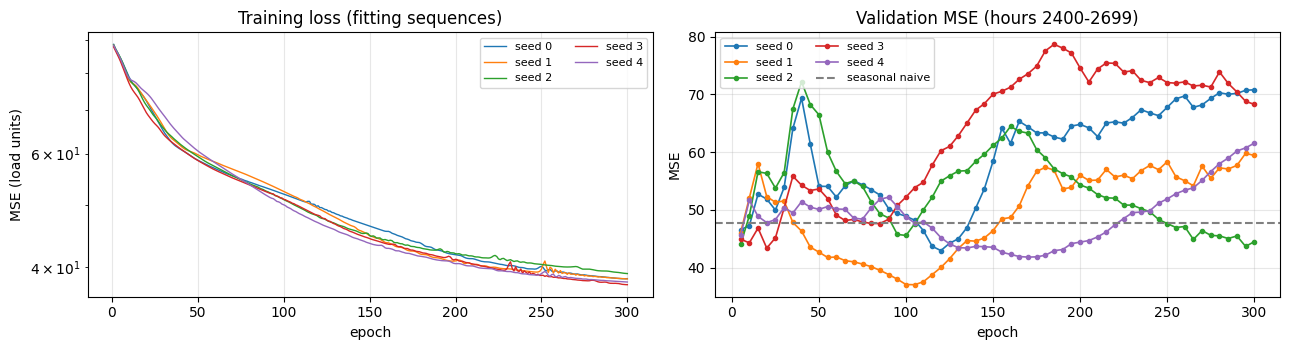

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for seed, record in enumerate(records):
    axes[0].plot(np.arange(1, 301), np.array(record["train_loss"]) * std ** 2, lw=1, label=f"seed {seed}")
    axes[1].plot(record["epoch"], record["val_mse"], lw=1.2, marker=".", label=f"seed {seed}")
print("training MSE at epoch 1:  ", np.round([r["train_loss"][0] * std ** 2 for r in records], 1))
print("training MSE at epoch 300:", np.round([r["train_loss"][-1] * std ** 2 for r in records], 1))
axes[0].set(yscale="log", title="Training loss (fitting sequences)", xlabel="epoch", ylabel="MSE (load units)")
axes[1].axhline(mse(y_val, naive_val), color="gray", ls="--", label="seasonal naive")
axes[1].set(title="Validation MSE (hours 2400-2699)", xlabel="epoch", ylabel="MSE")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

The training loss falls smoothly for all five seeds, from about 88 to about 38 in load units. The validation MSE behaves very differently. It starts just below the seasonal naive forecast (47.70) at epoch 5, climbs above it within the first 50 epochs for most seeds, and then wanders: seeds 0 and 3 end near 70, while seed 2 comes back down and reaches its best value at epoch 295. Early stopping picks epochs between 20 and 295, with validation MSEs from 37.03 to 43.66, all below the seasonal naive forecast, but by less than the LSTMs of Chapter 18 (26.28 to 36.52). The network starts to overfit the 2,400 hours of the fitting period early, and the validation period, with its drop of the load level, is hard for it.

## Forecasts on the test period

test MSE by seed: [18.45 20.22 16.08 22.75 17.14]
mean 18.93, range 16.08-22.75
ensemble of the 5 seeds: 16.47
seasonal naive:          22.29


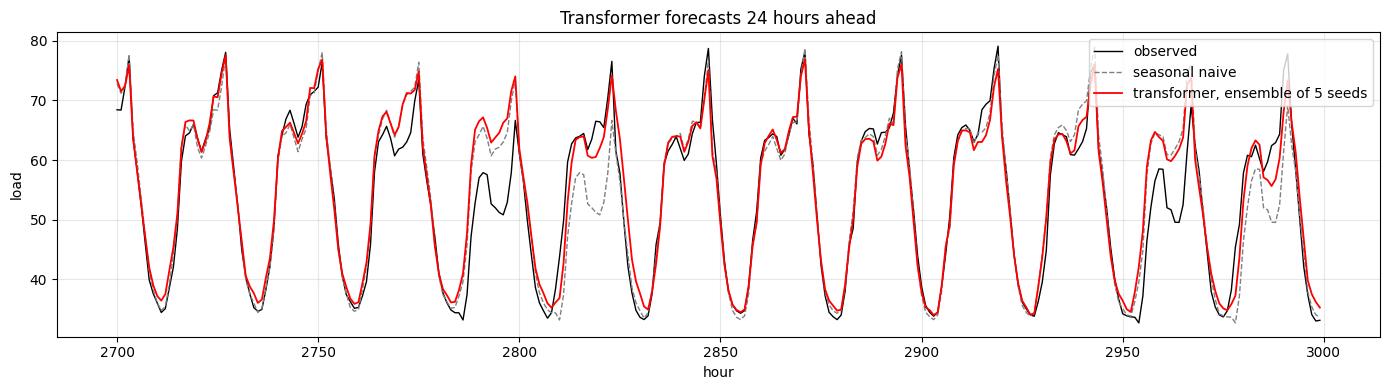

In [19]:
forecasts = np.array([transformer_forecast(net, test) for net in nets])
seed_mse = [mse(y_test, fc) for fc in forecasts]
y_transformer = forecasts.mean(axis=0)
print("test MSE by seed:", np.round(seed_mse, 2))
print(f"mean {np.mean(seed_mse):.2f}, range {np.min(seed_mse):.2f}-{np.max(seed_mse):.2f}")
print(f"ensemble of the 5 seeds: {mse(y_test, y_transformer):.2f}")
print(f"seasonal naive:          {mse(y_test, naive_test):.2f}")

ax = run_sequence_plot(y_test, x=test_hours, color="black", figsize=(14, 4), label="observed",
                       xlabel="hour", ylabel="load", title="Transformer forecasts 24 hours ahead")
ax.plot(test_hours, naive_test, color="gray", ls="--", lw=1, label="seasonal naive")
ax.plot(test_hours, y_transformer, color="red", lw=1.3, label="transformer, ensemble of 5 seeds")
ax.legend(); plt.tight_layout(); plt.show()

Four of the five transformers beat the seasonal naive forecast (22.29) on the test period, and the fifth, seed 3, is slightly worse (22.75). The test MSEs range from 16.08 to 22.75, with a mean of 18.93, and the ensemble of the five reaches 16.47. That is about as good as the MLP of Chapter 16 (18.48) and a single LSTM (17.82), and worse than the ensemble of LSTMs (14.47). The plot shows the same pattern as the LSTM: the transformer misses the two low days, around hours 2790 and 2955, and forecasts an ordinary day, but it does not repeat them on the following days, as the seasonal naive forecast does.

## Without positional embeddings

To see what the positional embeddings contribute, we train the same five networks without them, everything else unchanged. The causal mask still breaks the symmetry between the tokens to some extent, since token $j$ sees $j$ patches, but the last token sees all 14 patches as a set, without knowing which one is which day.

In [20]:
start = time.perf_counter()
no_position_mse, no_position_fc = [], []
for seed in range(5):
    net_np, record_np = fit_with_early_stopping(seed, positions=False)
    no_position_fc.append(transformer_forecast(net_np, test))
    no_position_mse.append(mse(y_test, no_position_fc[-1]))
    print(f"seed {seed}: stopped at epoch {record_np['best_epoch']:3d}, validation MSE {min(record_np['val_mse']):.2f}, "
          f"test MSE {no_position_mse[-1]:.2f}  (with positions: {seed_mse[seed]:.2f})")
print(f"mean {np.mean(no_position_mse):.2f}, ensemble {mse(y_test, np.mean(no_position_fc, axis=0)):.2f}")
print(f"5 fits in {time.perf_counter() - start:.0f} s")

seed 0: stopped at epoch 105, validation MSE 43.23, test MSE 19.37  (with positions: 18.45)
seed 1: stopped at epoch  75, validation MSE 39.76, test MSE 18.27  (with positions: 20.22)
seed 2: stopped at epoch 290, validation MSE 38.55, test MSE 20.49  (with positions: 16.08)
seed 3: stopped at epoch  20, validation MSE 42.79, test MSE 22.26  (with positions: 22.75)
seed 4: stopped at epoch   5, validation MSE 43.38, test MSE 22.35  (with positions: 17.14)
mean 20.55, ensemble 17.24
5 fits in 51 s


seed 1: stopped at epoch  75, validation MSE 39.76, test MSE 18.27  (with positions: 20.22)


seed 2: stopped at epoch 290, validation MSE 38.55, test MSE 20.49  (with positions: 16.08)


seed 3: stopped at epoch  20, validation MSE 42.79, test MSE 22.26  (with positions: 22.75)


seed 4: stopped at epoch   5, validation MSE 43.38, test MSE 22.35  (with positions: 17.14)
mean 20.55, ensemble 17.24
5 fits in 29 s


Without positional embeddings, the mean test MSE rises from 18.93 to 20.55, and the ensemble from 16.47 to 17.24. Three seeds are worse without them and two are better, with differences between $-1.95$ and $+5.21$ per seed. The positional embeddings help on average, but by less than the spread between the seeds: the network makes little use of the order of the days.

## Comparison with the earlier chapters

In [21]:
comparison = pd.DataFrame({
    "test MSE": [mse(y_test, naive_test), 18.48, 12.45, 16.17, 17.82, 14.47,
                 mse(y_test, y_analog), np.mean(seed_mse), mse(y_test, y_transformer)],
    "source": ["computed above", "Chapter 16", "Chapter 16", "Chapter 17", "Chapter 18", "Chapter 18",
               "computed above", "computed above", "computed above"]},
    index=["seasonal naive", "MLP, 48-hour window (mean of 3 seeds)", "linear, 168-hour window",
           "ESN, 900 units, ridge readout", "LSTM, 16 units (mean of 5 seeds)", "LSTM, ensemble of 5 seeds",
           "attention forecast, no training", "transformer (mean of 5 seeds)", "transformer, ensemble of 5 seeds"])
comparison.round(2)

,test MSE,source
seasonal naive,22.29,computed above
"MLP, 48-hour window (mean of 3 seeds)",18.48,Chapter 16
"linear, 168-hour window",12.45,Chapter 16
"ESN, 900 units, ridge readout",16.17,Chapter 17
"LSTM, 16 units (mean of 5 seeds)",17.82,Chapter 18
"LSTM, ensemble of 5 seeds",14.47,Chapter 18
"attention forecast, no training",8.76,computed above
transformer (mean of 5 seeds),18.93,computed above
"transformer, ensemble of 5 seeds",16.47,computed above


The attention forecast without training is the best model of Chapters 16 to 19, with a test MSE of 8.76, ahead of the linear model with a one-week window (12.45), whose window was chosen after looking at the test period. The trained transformer is in the middle of the table with the other neural networks: its ensemble (16.47) is about as good as the ESN (16.17) and worse than the LSTM ensemble (14.47).

The two attention models differ in what they can look up. The attention forecast compares the last week with every week of the history, up to about 2,800 keys, and passes on what actually happened after the most similar ones. The trained transformer sees only the last 14 days, and it must learn from 409 overlapping sequences, about 100 days of data, how to turn them into a forecast: its 952 weights have to learn the weekly pattern that the attention forecast gets for free from its keys and values. This is the general picture for transformers in forecasting. They shine when trained on very large data sets, which is the reason for the success of large language models, while on small data, simple models are hard to beat: Zeng et al. (2023) found that a one-layer linear model beat several transformer forecasters on standard benchmarks. Attention as a lookup in the history of the series, on the other hand, is a strong forecasting tool even without training.

The caveats of Chapter 18 apply: the test period is only 12.5 days long, and the test MSEs of the neural networks vary by several units from seed to seed (16.08 to 22.75 for the transformer).

## Looking inside the transformer

The attention weights tell us where each token looks. We run the five networks on the 300 test sequences, keep the attention matrices, and average, over the test origins, the weights of the last token, the one that makes the forecast, over the 14 days of its input. We label each day by how many days it lies before the target day: the last patch is 1 day before, and patch 8 is 7 days before, the same day of the week as the target.

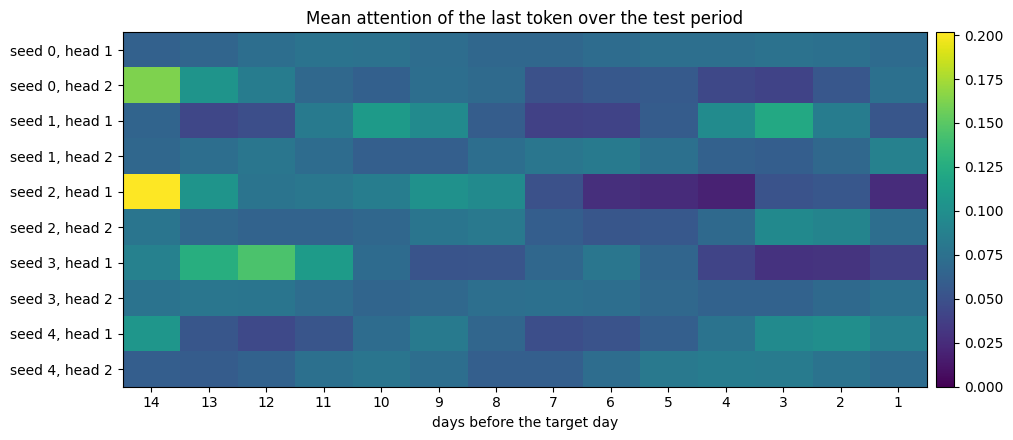

,14 days before,7 days before,1 day before,effective days (median)
"seed 0, head 1",0.06,0.07,0.07,11.26
"seed 0, head 2",0.16,0.05,0.07,5.60
"seed 1, head 1",0.06,0.04,0.05,6.36
"seed 1, head 2",0.07,0.08,0.09,10.93
"seed 2, head 1",0.20,0.05,0.03,3.22
"seed 2, head 2",0.08,0.06,0.07,8.77
"seed 3, head 1",0.09,0.07,0.04,10.58
"seed 3, head 2",0.08,0.07,0.07,13.34
"seed 4, head 1",0.11,0.05,0.09,7.74
"seed 4, head 2",0.06,0.06,0.07,10.46


In [22]:
X_test = make_patches(origins[test])
A_last = np.array([net.forward(X_test)[1]["blocks"][0]["A"][:, :, -1, :] for net in nets])  # (seed, origin, head, patch)
mean_weights = A_last.mean(axis=1).reshape(-1, 14)     # rows: (seed, head); columns: patches 1-14
effective_days = np.median(1 / np.sum(A_last ** 2, axis=-1), axis=1).ravel()
labels = [f"seed {s}, head {h + 1}" for s in range(5) for h in range(2)]
days_before = 15 - np.arange(1, 15)                    # patch j lies 15 - j days before the target day

fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(mean_weights, aspect="auto", cmap="viridis", vmin=0)
ax.set_xticks(np.arange(14), days_before)
ax.set_yticks(np.arange(10), labels)
ax.set(title="Mean attention of the last token over the test period", xlabel="days before the target day")
fig.colorbar(im, ax=ax, pad=0.01)
plt.tight_layout(); plt.show()

pd.DataFrame({"14 days before": mean_weights[:, 0], "7 days before": mean_weights[:, 7],
              "1 day before": mean_weights[:, 13], "effective days (median)": effective_days},
             index=labels).round(2)

No head singles out the day one week before the target day, the information that anticipates the low days: its mean weights, between 0.04 and 0.08, are close to an even share of $1/14 = 0.07$. A few heads have preferences: two of them put 0.16 and 0.20 of their weight, on average, on the oldest day, 14 days before the target, which is the same day of the week two weeks earlier, and seed 3's first head favors the days 11 to 13 days before. The heads also differ in how sharply they attend: at a typical origin, the effective number of days ranges from 3.2 (seed 2, head 1) to 13.3 (seed 3, head 2), out of 14. A head can be sharp at each origin and still have spread-out mean weights, when it looks at different days at different origins: it then responds to the content of the days, not to a fixed lag.

Like the LSTM of Chapter 18, the transformer had direct access to the load one week earlier, here in a single attention step instead of 144 recurrent steps, and it did not learn to use it from about 100 days of data. A short path makes a long-range dependency learnable; it does not make it learned. The remedies of Chapter 18 apply here as well: give the network the information directly, for example a day-of-week embedding added to each token, as a temporal embedding, or train on much more data, for example on many load series at once. That is how the large pretrained transformers for time series, the time series foundation models, are built.

## The same model in PyTorch

With a deep-learning library, we only define the forward pass, and the library computes the gradients by automatic differentiation. The code below, not executed here, builds a model like ours in PyTorch and trains it on the same arrays `X_fit`, `Y_fit` and `mask`. PyTorch calls its block `TransformerEncoderLayer`; with a causal mask, it is the block of a decoder-only model like ours or GPT. It includes layer normalization, here before each sub-layer as in GPT-2 (`norm_first=True`), and dropout, which we switch off.

```python
import torch
from torch import nn


class PatchTransformer(nn.Module):
    def __init__(self, patch=24, n_tokens=14, d=8, n_heads=2, d_ff=16):
        super().__init__()
        self.embed = nn.Linear(patch, d)
        position = torch.arange(n_tokens)[:, None]
        omega = 10000.0 ** (-torch.arange(0, d, 2) / d)
        P = torch.zeros(n_tokens, d)
        P[:, 0::2], P[:, 1::2] = torch.sin(position * omega), torch.cos(position * omega)
        self.register_buffer("P", P)                                       # fixed, not trained
        self.register_buffer("mask", nn.Transformer.generate_square_subsequent_mask(n_tokens))
        self.block = nn.TransformerEncoderLayer(d, n_heads, dim_feedforward=d_ff, dropout=0.0,
                                                batch_first=True, norm_first=True)
        self.readout = nn.Linear(d, patch)

    def forward(self, x):                                  # x: (B, n, patch)
        e = self.embed(x) + self.P
        e = self.block(e, src_mask=self.mask, is_causal=True)
        return self.readout(e)                             # (B, n, patch)


model = PatchTransformer()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
X_t, Y_t, mask_t = (torch.tensor(a, dtype=torch.float32) for a in (X_fit, Y_fit, mask))
for epoch in range(300):
    optimizer.zero_grad()
    loss = (((model(X_t) - Y_t) * mask_t) ** 2).sum() / mask_t.sum()
    loss.backward()                                        # backpropagation, automatically
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
```

Stacking blocks is `nn.TransformerEncoder(block, num_layers=3)`, and `nn.MultiheadAttention` provides the attention layer alone.

---

# Summary

**Transformer**: an auto-regressive model that predicts each token from the tokens before it, built from a stack of identical blocks. Each block has an attention layer, which mixes information across the positions, and a feed-forward network, which transforms each position separately, both with residual connections. All positions are processed in parallel, and any two positions are one attention step apart.

- **Tokens and embeddings.** Text is cut into sub-word tokens, each represented by a learned embedding vector; a time series is usually cut into patches of consecutive values, embedded by a linear layer. The similarity of two embeddings is measured by their dot product or their cosine similarity. The daily patches of the Rome load are already embeddings in which days of the same kind lie close together.
- **Attention.** Each token gets a query $\mathbf{q}_i = \mathbf{W}_q^\top \mathbf{x}_i$, a key $\mathbf{k}_i = \mathbf{W}_k^\top \mathbf{x}_i$ and a value $\mathbf{v}_i = \mathbf{W}_v^\top \mathbf{x}_i$, and in matrix form,
$$\mathrm{Attention}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \mathrm{softmax}_{\text{row}}\left(\frac{\mathbf{Q}\mathbf{K}^\top}{\sqrt{d_k}} + \mathbf{M}\right)\mathbf{V}.$$
The scaling by $\sqrt{d_k}$ keeps the scores at unit variance; without it, the softmax saturates (the largest of 10 weights averages 0.93 for $d_k = 256$). Multi-head attention runs $H$ heads with their own projections, concatenates their outputs and mixes them with $\mathbf{W}_o$; with $H d_k = d$, it has $4d^2$ weights.
- **Order.** Self-attention is permutation-equivariant, so positional embeddings, learned or sinusoidal, are added to the input tokens. For the sinusoidal ones, $\mathbf{p}_i^\top \mathbf{p}_j$ depends only on $i - j$. The causal mask $\mathbf{M}$, with $-\infty$ above the diagonal and applied before the softmax, keeps every position from seeing the future and lets one pass train on $n$ predictions at once.
- **Forecasting the load.** Attention with fixed projections, centered one-week windows as queries and keys and the following 24-hour changes as values, is the method of analogues in a new form. It reached a test MSE of 8.76, against 22.29 for the seasonal naive forecast, the best of Chapters 16 to 19, and it anticipated the low days. A one-block transformer with 952 parameters, trained on daily patches, reached 18.93 on average and 16.47 as an ensemble of five seeds, on par with the other neural networks, and none of its heads learned to look at the day one week before the target. Transformers need large training sets; on a short series, what attention can look up matters more than what it can learn.